# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Finn McLachlan, Thomas Sinclair, Sridhar, Bagus Awan**

## Setup

*Install any packages here, define any functions if needed, and load data.*

In [17]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster import hierarchy
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score, silhouette_samples, adjusted_rand_score
)
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", palette="colorblind")


In [18]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")
df_avg.head()


,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.133,0.152,0.169,0.143,0.136,0.130,0.126,0.120,0.120,0.120
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.721,0.971,0.849,0.799,0.861,0.752,0.727,0.695,0.677,0.669
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.934,0.973,1.264,0.990,1.054,0.988,0.918,0.887,0.854,0.836
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.483,0.704,0.683,0.530,0.676,0.530,0.496,0.460,0.438,0.427
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.578,0.700,0.861,0.645,0.739,0.642,0.583,0.547,0.514,0.495


# Introduction

*This section should include a brief introduction to the task and the data (assume this is a report you are delivering to a professional body (e.g. Scottish Government)).*

*State which supervised learning question you are answering.*

*Briefly outline the approaches being used (for both the clustering and your chosen supervised learning task) and the conclusions that you are able to draw.*

We have been tasked with performing an investigation into the river water levels, and whether predictions can be made about water levels in future. 

# Exploratory Data Analysis and Feature Engineering

*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

In [19]:
df_min.shape[0],df_avg.shape[0],df_max.shape[0] #notice they are all the same length

df_min.info()
#df

<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Columns: 4382 entries, County to 08/10/2026
dtypes: float64(4379), str(3)
memory usage: 13.1 MB


In [20]:
# Will not be able to use for clustering, records every observation, every day. Could be useful later though

#elongate df to put in better form

df_avg_long = df_avg.melt(
    id_vars=["County","Station_Name","Observation_ID"],         
    var_name="Date",           
    value_name="Avg_Level"    
)

df_min_long = df_min.melt(
    id_vars=["County","Station_Name","Observation_ID"],        
    var_name="Date",           
    value_name="Min_Level"         
)
df_max_long = df_max.melt(
    id_vars=["County","Station_Name","Observation_ID"],         
    var_name="Date",           
    value_name="Max_Level"         
)

#combine if certain values are equal (just in case)
df_main = (
    df_min_long
    .merge(df_max_long, on=["Observation_ID","County","Station_Name","Date"], how="inner")
    .merge(df_avg_long, on=["Observation_ID","County","Station_Name","Date"], how="inner")
)

#drop nas if min max and avg are na
df_main = df_main.dropna(subset=["Min_Level", "Max_Level", "Avg_Level"], how="all")
#df_main.shape

# convert date column (string) to datetime, drop rows with unparseable dates
df_main["Date"] = pd.to_datetime(df_main["Date"], dayfirst=True, errors="coerce")
n_bad = df_main["Date"].isna().sum()
if n_bad:
    print(f"Dropping {n_bad} rows with unparseable dates")
    df_main = df_main.dropna(subset=["Date"]).copy()





In [21]:
df_main.info()
df_main.head()
# desription
print("\nCleaned level distribution:")
print(df_main[["Avg_Level", "Min_Level", "Max_Level"]]
      .describe().T.round(3))

<class 'pandas.DataFrame'>
Index: 1190691 entries, 122 to 1716567
Data columns (total 7 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   County          1190691 non-null  str           
 1   Station_Name    1190691 non-null  str           
 2   Observation_ID  1190691 non-null  str           
 3   Date            1190691 non-null  datetime64[us]
 4   Min_Level       1190691 non-null  float64       
 5   Max_Level       1190691 non-null  float64       
 6   Avg_Level       1190691 non-null  float64       
dtypes: datetime64[us](1), float64(3), str(3)
memory usage: 72.7 MB

Cleaned level distribution:
               count    mean       std         min    25%    50%    75%  \
Avg_Level  1190691.0   3.884  1185.799 -190475.436  0.292  0.477  0.763   
Min_Level  1190691.0 -22.948  5019.457 -999999.999  0.250  0.430  0.670   
Max_Level  1190691.0  40.347  6282.618     -29.638  0.324  0.540  0.935   

                  

In [22]:
# function to detect tidal observations, Look at dataset details in project brief
def tidal_flag(observation_id):
    """1 = tidal, 0 = non-tidal (default)."""
    s = str(observation_id).lower()
    if "non-tidal" in s or "nontidal" in s:
        return 0
    if "tidal" in s:
        return 1
    return 0

obs_lookup = df_main[["Observation_ID"]].drop_duplicates()
obs_lookup["is_tidal"] = obs_lookup["Observation_ID"].map(tidal_flag).astype(int)
print("Station-level tidal flag:")
print(obs_lookup["is_tidal"].value_counts())

df_main = df_main.merge(obs_lookup, on="Observation_ID", how="left")

df_main.info()



Station-level tidal flag:
is_tidal
0    380
1     12
Name: count, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 1190691 entries, 0 to 1190690
Data columns (total 8 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   County          1190691 non-null  str           
 1   Station_Name    1190691 non-null  str           
 2   Observation_ID  1190691 non-null  str           
 3   Date            1190691 non-null  datetime64[us]
 4   Min_Level       1190691 non-null  float64       
 5   Max_Level       1190691 non-null  float64       
 6   Avg_Level       1190691 non-null  float64       
 7   is_tidal        1190691 non-null  int64         
dtypes: datetime64[us](1), float64(3), int64(1), str(3)
memory usage: 72.7 MB


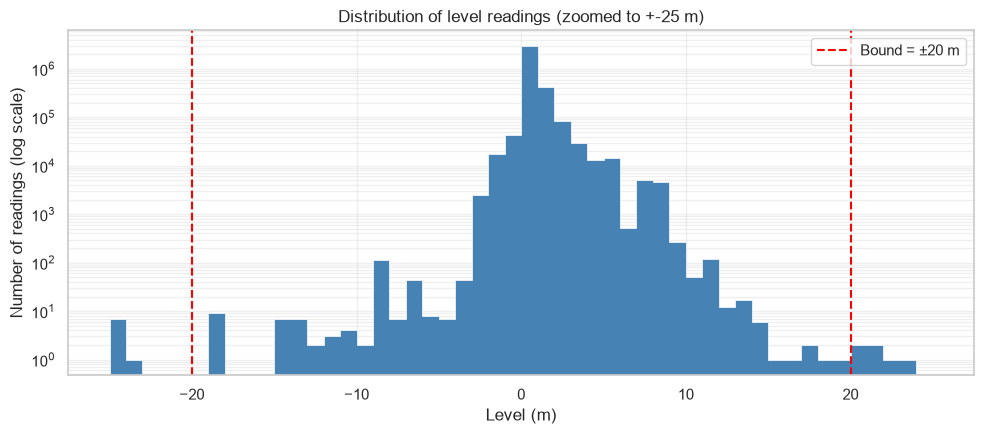

In [23]:
# Clearly description states theres problems within the data
# Plot to explore possible bounds. Right now we are using a bound of 20 metres, but this is arbitrary. We can see from the histogram that there are some extreme values that are not realistic for Scottish rivers, 
# and we want to filter those out.

vals = df_main[["Avg_Level", "Min_Level", "Max_Level"]].to_numpy().ravel()
vals = vals[np.isfinite(vals)]

fig, ax = plt.subplots(figsize=(10, 4.5))

# Plot standard histogram, but limit the x-range to -25 to 25
# We use 50 bins, which gives a bin width of 1 metre (very intuitive)
ax.hist(vals, bins=50, range=(-25, 25), 
        histtype="stepfilled", edgecolor="white", linewidth=0.5,
        color="steelblue", log=True)

# Add the bounds
ax.axvline(-20, ls="--", color="red", lw=1.5, label="Bound = ±20 m")
ax.axvline( 20, ls="--", color="red", lw=1.5)

ax.set(
    xlabel="Level (m)",
    ylabel="Number of readings (log scale)",
    title="Distribution of level readings (zoomed to +-25 m)"
)
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

#NOTE: The histogram shows the distribution of river level readings, with the bounds indicated by red dashed lines. This bound was used to filter out unrealistic values, such as 999999, -99, and 99, 
# which are not representative of actual river levels in Scotland. The histogram is plotted on a logarithmic scale to better visualize the distribution of readings across the range of -25 to 25 meters.
# Look at .describe() to see why this was needed.

In [32]:
# Implement this bound into data river we consulted links like; (https://en.wikipedia.org/wiki/1993_Perth_flood), https://waterlevels.sepa.org.uk/Station/234235, as well as tidal resources, which meant we
#  could capture the tidal observations within our cleaning of the dataset(https://marine.gov.scot/sma/maps/423)
BOUND = 20   
for c in ["Avg_Level", "Min_Level", "Max_Level"]:
    df_main.loc[df_main[c].abs() > BOUND, c] = np.nan

#Column for daily range 
df_main["Range_Level"] = df_main["Max_Level"] - df_main["Min_Level"] #Range calculated after nulling bugged values, otherwise would be unrealistic

print("\nCleaned level distribution:")
print(df_main[["Avg_Level", "Min_Level", "Max_Level", "Range_Level"]]
      .describe().T.round(3))

#NOTE: The cleaned level distribution shows the summary statistics for the average, minimum, maximum, and range of river levels after filtering out unrealistic values. 
# The range is calculated as the difference between the maximum and minimum levels for each observation.  


Cleaned level distribution:
                 count   mean    std     min    25%    50%    75%     max
Avg_Level    1188139.0  0.652  0.723 -13.187  0.291  0.476  0.761  16.542
Min_Level    1188186.0  0.508  0.692 -18.816  0.250  0.430  0.670  13.800
Max_Level    1188156.0  0.812  0.928  -9.000  0.324  0.540  0.930  19.590
Range_Level  1188110.0  0.304  0.760   0.000  0.012  0.043  0.190  38.406


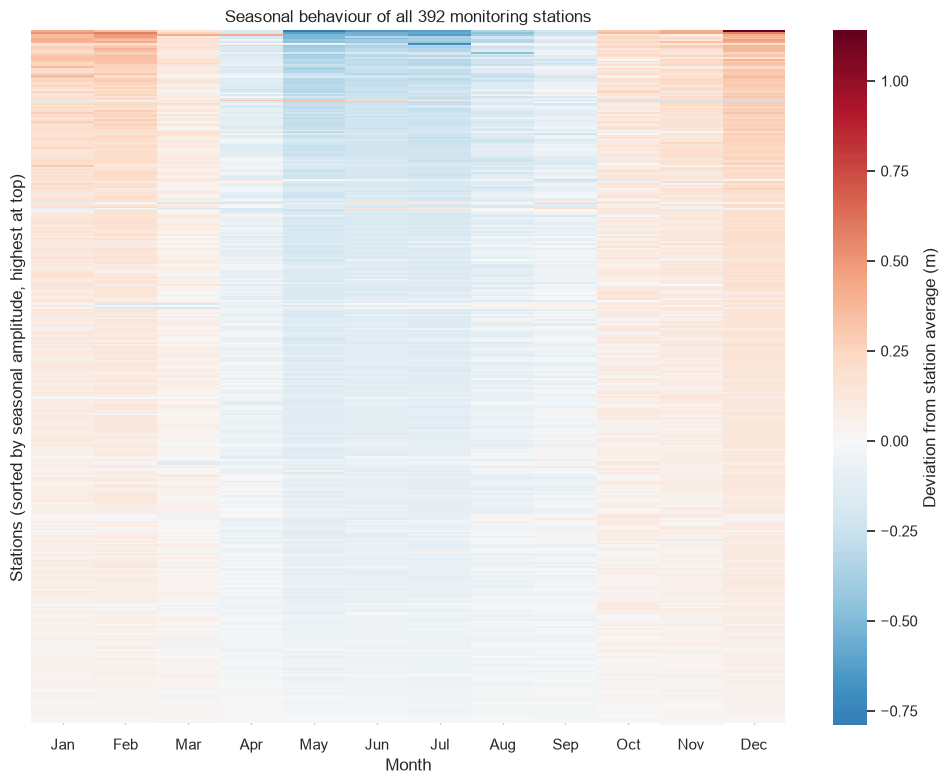

In [ ]:
# Monthly average at each station
monthly_avg = (
    df_main.assign(month=df_main["Date"].dt.month)
    .groupby(["Observation_ID", "month"])["Avg_Level"]
    .mean()
    .unstack()
)

# normalise each station (subtract its own mean)
row_norm = monthly_avg.sub(monthly_avg.mean(axis=1), axis=0) #month average-yearly average


seasonal_amp = monthly_avg.max(axis=1) - monthly_avg.min(axis=1)
row_norm = row_norm.loc[seasonal_amp.sort_values(ascending=False).index] #sorts in order of highest difference between summer and winter

# Plot heatmap of seasonal behaviour of all 392 monitoring stations
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    row_norm,
    cmap="RdBu_r",           
    center=0,
    yticklabels=False,       # so we don't see the 392 station names
    xticklabels=["Jan","Feb","Mar","Apr","May","Jun",
                 "Jul","Aug","Sep","Oct","Nov","Dec"],
    cbar_kws={"label": "Deviation from station average (m)"},
    ax=ax,
)
ax.set_xlabel("Month")
ax.set_ylabel("Stations (sorted by seasonal amplitude, highest at top)")
ax.set_title("Seasonal behaviour of all 392 monitoring stations")
plt.tight_layout()
plt.show()

In [ ]:
# We have 1.19m rows of daily data. KMeans needs 392 rows (one per station). We are clustering by stations
# So we group by station and calculate summary statistics

station = df_main.groupby("Observation_ID").agg(
    County=("County", "first"), #take the first county name, should be the same for all rows of that same station
    Station_Name=("Station_Name", "first"),
    is_tidal=("is_tidal", "first"),
    avg_level=("Avg_Level", "mean"),           # Typical water level
    var_level=("Avg_Level", "std"),            # How much it fluctuates
    daily_range=("Range_Level", "mean"),       # Average daily min-max swing
    n_obs=("Avg_Level", "count")               # Number of real readings
).reset_index()

#NOTE: in heatmap above we see clear seasonal changes.

# Add seasonal amplitude (how much the river changes between summer and winter)
monthly = df_main.groupby(["Observation_ID", df_main["Date"].dt.month])["Avg_Level"].mean().unstack()
station["seasonal_amp"] = monthly.max(axis=1) - monthly.min(axis=1)

print(f"We now have {station.shape[0]} rows, one for each station.")

# We utilise scaling as not all features have same number of observations
# These are the features that describe a river's behaviour
features = ["avg_level", "var_level", "daily_range", "seasonal_amp", "n_obs", "is_tidal"]

# We scale them so they all have a mean of 0 and a standard deviation of 1.
# This prevents features with large numbers (like n_obs) from overpowering small numbers (like avg_level).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(station[features].fillna(0))

print("Data is scaled and ready for KMeans.")

X_scaled

We now have 392 rows, one for each station.
Data is scaled and ready for KMeans.


array([[-0.45177069, -0.16151604, -0.36756467,  0.        ,  0.41264827,
        -0.17770466],
       [ 0.19090682, -0.23665057, -0.25529792,  0.        ,  0.40323543,
        -0.17770466],
       [ 0.60393677,  0.26044413, -0.18495332,  0.        ,  0.40951066,
        -0.17770466],
       ...,
       [-0.14320733, -0.04141331, -0.14615843,  0.        ,  0.30910701,
        -0.17770466],
       [ 0.14677045,  0.14451064,  0.00375143,  0.        ,  0.39852901,
        -0.17770466],
       [-0.15867694, -0.18621684, -0.14908276,  0.        , -2.81438776,
        -0.17770466]], shape=(392, 6))

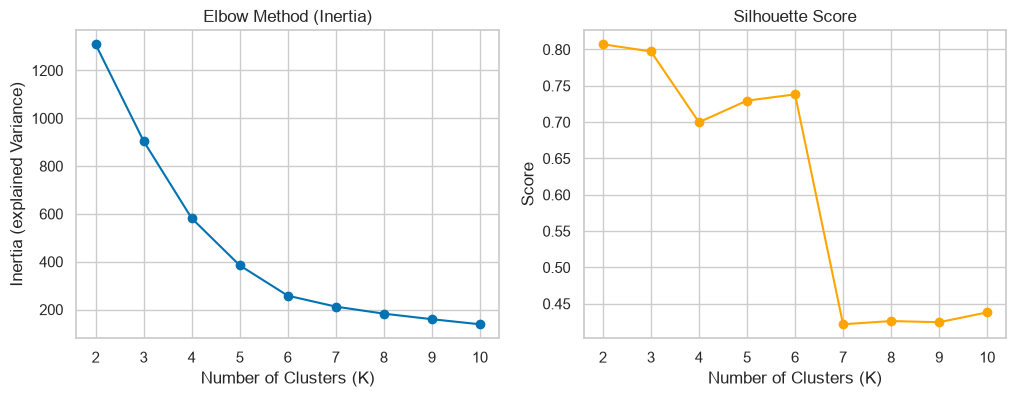

In [34]:
# Use k-means++ as from workshop we saw faster convergence and better clustering results than random initialisation.
#  We will try different values of K (number of clusters) to find the optimal number of clusters for our data.

K_range = range(2, 11)
inertias, silhouettes = [], []

for k in K_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=0) # n_init = 10 to run the algorithm 10 times with different centroid seeds and take the best one (gives us the best result)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(K_range, inertias, marker="o")
ax1.set_title("Elbow Method (Inertia)")
ax1.set_xlabel("Number of Clusters (K)")
ax1.set_ylabel("Inertia (explained Variance)")

ax2.plot(K_range, silhouettes, marker="o", color="orange")
ax2.set_title("Silhouette Score")
ax2.set_xlabel("Number of Clusters (K)")
ax2.set_ylabel("Score")
plt.show()

# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

*Include a list of all references cited in the text.*

In [27]:
# Run the following to render to PDF
#!jupyter nbconvert --to pdf project.ipynb